# Lab 14 — Explaining Clinical Models: SHAP, Permutation Importance, and ECG Saliency Maps

**AI in Healthcare · Unit IV · B.Tech AI, Third Year · About 120 minutes**
**Lecture:** [Session 5 — Interpretability and explainability in clinical practice](../lectures/session-05-explainability-skills.md)
**Previous lab:** [Lab 13 — Validating a clinical prediction model](lab-13-model-validation.ipynb)
**Runs on:** a laptop CPU (the ECG model trains in a few minutes); a Kaggle notebook also works.

## Objectives

1. **Explain a tabular model two ways** — permutation importance (global) and SHAP (local) — and compare a logistic regression with a gradient-boosted model.
2. **Test whether two accurate models tell the same story** about the same patient.
3. **Compute saliency maps** for the Unit II ECG 1D CNN with three methods: gradient, gradient × input, and occlusion.
4. **Run a sanity check**: do the maps change when the model's weights are randomised?
5. **Test a suspected shortcut**: can beat length alone separate beat classes?

**Prerequisites:** Session 5 lecture notes (coefficients, contributions, permutation importance, saliency, sanity checks); the Unit II ECG lecture (beat classes N, S, V, F, Q; zero padding); Lab 13 (the heart-disease model and the four UCI sites). PyTorch basics: a forward pass and `.backward()`.

## Data

| | Part 1: heart disease | Part 2: ECG beats |
|---|---|---|
| Source | UCI Heart Disease, Cleveland and Budapest (CC BY 4.0, [doi:10.24432/C52P4X](https://doi.org/10.24432/C52P4X)) | MIT-BIH portion of the Kaggle [ECG Heartbeat Categorization Dataset](https://www.kaggle.com/datasets/shayanfazeli/heartbeat), derived from the [MIT-BIH Arrhythmia Database](https://physionet.org/content/mitdb/1.0.0/) |
| One row is | One patient | One beat: 187 values at 125 samples per second, zero-padded at the end |
| Size | About 50 KB, downloaded on first run | `mitbih_train.csv` (87,554 beats, about 393 MiB) and `mitbih_test.csv` (21,892 beats, about 98 MiB) — **not downloaded by this notebook** |

**Getting the ECG files.** The notebook looks, in order, in: any folder under `/kaggle/input/` (on Kaggle, add the dataset *shayanfazeli/heartbeat* to the notebook); `module2/lectures/data/ecg_hb_clf/` in this repository (where the Unit II notebooks keep it); the course folder `module 2/lab4/ecg/data/`, and `lab14_data/` next to this notebook. Check the Kaggle page's licence before redistributing the files.

## Deliverables

Submit the notebook run from top to bottom, with all exercise code completed, every ✍️ answer written, and the reflection in Part 3.

## Setup — 10 minutes

Libraries: NumPy, pandas, scikit-learn, matplotlib, SciPy, PyTorch and **SHAP**. SHAP is preinstalled on Kaggle; elsewhere, install it yourself before starting (`pip install shap`). The notebook never installs packages.

**Files written:** the two UCI files go to `lab14_data/` (reused on reruns). Nothing else is written.

In [1]:
import time
import urllib.request
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
from scipy.stats import spearmanr
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    import shap
except ImportError as err:
    raise ImportError("SHAP is not installed. Install it (pip install shap) and restart the kernel.") from err

SEED = 42
DATA_DIR = Path.cwd() / "lab14_data"
DATA_DIR.mkdir(exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"scikit-learn {sklearn.__version__} | SHAP {shap.__version__} | torch {torch.__version__} | device {DEVICE}")


def check(description, condition):
    print(("PASS  " if condition else "CHECK ") + description)

scikit-learn 1.7.2 | SHAP 0.51.0 | torch 2.15.0+cpu | device cpu


C:\Users\anshu\AppData\Local\Temp\lab14runtime\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part 1 — Explaining the heart-disease model (40 minutes)

We reuse the Session 3–5 setup: eight inputs recorded at all four UCI sites, models trained on **Cleveland**, and the **Budapest** patients as external data for permutation importance. We compare two models:

- the **logistic regression** from Sessions 3–5;
- a **gradient-boosted tree ensemble** (many shallow decision trees added together), which can learn non-linear effects and interactions.

In [2]:
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/"
UCI_COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
               "exang", "oldpeak", "slope", "ca", "thal", "num"]
CORE = ["age", "sex", "cp", "trestbps", "thalach", "exang", "oldpeak", "restecg"]


def load_site(fname):
    path = DATA_DIR / fname
    if not path.exists():
        urllib.request.urlretrieve(UCI_URL + fname, path)
    df = pd.read_csv(path, header=None, names=UCI_COLUMNS, na_values="?")
    df["target"] = (df["num"] > 0).astype(int)
    return df


def design(df):
    x = df[CORE].copy()
    x[["cp", "restecg"]] = x[["cp", "restecg"]].astype(int)
    x = pd.get_dummies(x, columns=["cp", "restecg"], dtype=float)
    for col in ["cp_1", "cp_2", "cp_3", "cp_4", "restecg_0", "restecg_1", "restecg_2"]:
        if col not in x:
            x[col] = 0.0
    return x[sorted(x.columns)].drop(columns=["cp_1", "restecg_0"])


cle = load_site("processed.cleveland.data")
bud = load_site("processed.hungarian.data")
bud = bud[bud[CORE].notna().all(axis=1)].reset_index(drop=True)
X_cle, y_cle = design(cle), cle["target"].to_numpy()

MODELS = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_cle, y_cle),
    "gradient boosting": GradientBoostingClassifier(n_estimators=200, max_depth=2, learning_rate=0.05,
                                                    subsample=0.8, random_state=0).fit(X_cle, y_cle),
}
for name, model in MODELS.items():
    auc = roc_auc_score(bud["target"], model.predict_proba(design(bud))[:, 1])
    print(f"{name:20} Budapest AUROC {auc:.3f}")

logistic regression  Budapest AUROC 0.875
gradient boosting    Budapest AUROC 0.884


### Exercise 1.1 — Permutation importance on external data

Complete `permutation_importance_auroc`. For each **raw** input in `CORE`, shuffle that column of `df` (so a one-hot group such as chest-pain type moves together), recompute AUROC, and record the drop from the unshuffled AUROC. Repeat `n_repeats` times and return the mean drop and the 2.5th and 97.5th percentiles of the drops.

In [3]:
def permutation_importance_auroc(model, df, n_repeats=100, seed=SEED):
    rng = np.random.default_rng(seed)
    y = df["target"].to_numpy()
    base = roc_auc_score(y, model.predict_proba(design(df))[:, 1])
    rows = []
    for col in CORE:
        drops = np.empty(n_repeats)
        shuffled = df.copy()
        for repeat in range(n_repeats):
            shuffled[col] = rng.permutation(df[col].to_numpy())
            shuffled_auc = roc_auc_score(y, model.predict_proba(design(shuffled))[:, 1])
            drops[repeat] = base - shuffled_auc
        lower, upper = np.percentile(drops, [2.5, 97.5])
        rows.append({"input": col, "mean drop": drops.mean(), "2.5%": lower, "97.5%": upper})
    return pd.DataFrame(rows).set_index("input")


importance = pd.concat({name: permutation_importance_auroc(m, bud) for name, m in MODELS.items()}, axis=1)
display(importance.sort_values(("logistic regression", "mean drop"), ascending=False).round(4))
check("chest-pain type matters for logistic regression",
      importance[("logistic regression", "mean drop")].get("cp", 0) > 0.03)

logistic regression                 gradient boosting                
                   mean drop    2.5%   97.5%         mean drop    2.5%   97.5%
input                                                                         
cp                    0.0658  0.0418  0.0930            0.0836  0.0554  0.1190
oldpeak               0.0374  0.0236  0.0512            0.0467  0.0302  0.0635
sex                   0.0275  0.0093  0.0508            0.0201  0.0063  0.0365
exang                 0.0168  0.0085  0.0256            0.0149  0.0070  0.0238
thalach               0.0045 -0.0083  0.0163            0.0097 -0.0050  0.0303
trestbps             -0.0017 -0.0068  0.0035           -0.0007 -0.0106  0.0070
restecg              -0.0019 -0.0061  0.0020           -0.0002 -0.0015  0.0008
age                  -0.0022 -0.0063  0.0036            0.0000 -0.0058  0.0056

PASS  chest-pain type matters for logistic regression


✍️ **Your answer** (3–4 sentences): Do the two models rely on the same inputs at Budapest? Which inputs could you remove without a measurable loss, judging by the percentile ranges? Why is "importance at Budapest" not the same as "importance for heart disease"?

**Answer**

The four inputs with the largest permutation drops for both models on Budapest were chest-pain type, oldpeak (exercise-induced ST depression), sex, and exercise-induced angina. Chest-pain type ranked first, with a mean AUROC drop of 0.0658 for logistic regression and 0.0836 for gradient boosting. Age, resting blood pressure, maximum heart rate, and resting ECG are candidates for removal because their 2.5th–97.5th percentile ranges include zero in both models, although a refit on fewer inputs would be needed to verify the effect of removal. These ranges measure repeated-shuffle variability on one cohort, and the importance depends on the fitted model, correlated inputs, patient mix, and AUROC metric rather than establishing a causal role in heart disease.

### Exercise 1.2 — SHAP for one patient

SHAP divides one prediction into additive contributions. For a tree ensemble, `shap.TreeExplainer` computes them exactly in the model's **log-odds** units:

$$\text{model log-odds} = \text{base value} + \sum_j \text{SHAP}_j$$

The patient is the first Cleveland record from Session 5: risk 0.60 under logistic regression, *no disease* on angiography. Complete the additivity check: add the base value and the SHAP values and compare with `decision_function`, which returns the gradient-boosted model's log-odds.

model log-odds: -0.239 | reconstructed: -0.23880065220667168
gradient-boosting risk: 0.441 | logistic-regression risk: 0.604
PASS  SHAP values add up to the model output


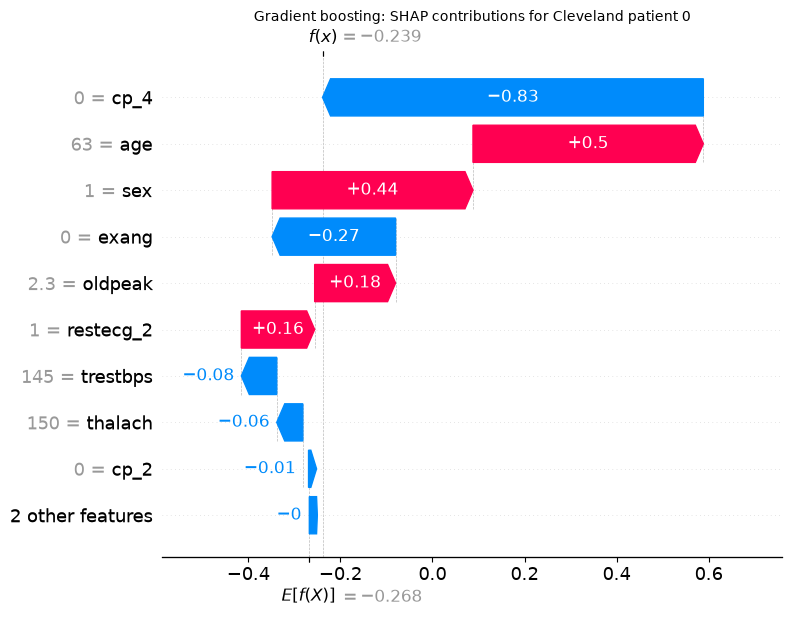

In [4]:
gb = MODELS["gradient boosting"]
explainer = shap.TreeExplainer(gb)
patient = X_cle.iloc[[0]]
sv = explainer(patient)                    # SHAP Explanation for one patient (log-odds units)

reconstructed = float(np.asarray(sv.base_values).item() + sv.values[0].sum())
model_log_odds = gb.decision_function(patient)[0]
print("model log-odds:", round(model_log_odds, 3), "| reconstructed:", reconstructed)
print("gradient-boosting risk:", round(gb.predict_proba(patient)[0, 1], 3),
      "| logistic-regression risk:", round(MODELS["logistic regression"].predict_proba(patient)[0, 1], 3))
check("SHAP values add up to the model output", abs(reconstructed - model_log_odds) < 1e-6)
shap.plots.waterfall(sv[0], show=False)
plt.title("Gradient boosting: SHAP contributions for Cleveland patient 0", fontsize=10)
plt.show()

In [5]:
# Logistic-regression contributions (Session 5): coefficient x standardised value
scaler, clf = MODELS["logistic regression"].named_steps.values()
lr_contrib = pd.Series(clf.coef_[0] * scaler.transform(patient)[0], index=X_cle.columns)
comparison = pd.DataFrame({"logistic regression": lr_contrib, "gradient boosting (SHAP)": sv.values[0]},
                          index=X_cle.columns)
comparison.sort_values("gradient boosting (SHAP)", key=abs, ascending=False).round(3)

,logistic regression,gradient boosting (SHAP)
cp_4,-1.005,-0.827
age,0.220,0.500
sex,0.540,0.436
exang,-0.263,-0.268
oldpeak,0.805,0.176
restecg_2,0.256,0.159
trestbps,0.226,-0.077
thalach,-0.008,-0.057
cp_2,-0.107,-0.012
cp_3,-0.048,-0.002


### Exercise 1.3 — Global SHAP view and two stories

The beeswarm plot below shows SHAP values for every Budapest patient: one dot per patient per input, coloured by the input's value (red high, blue low).

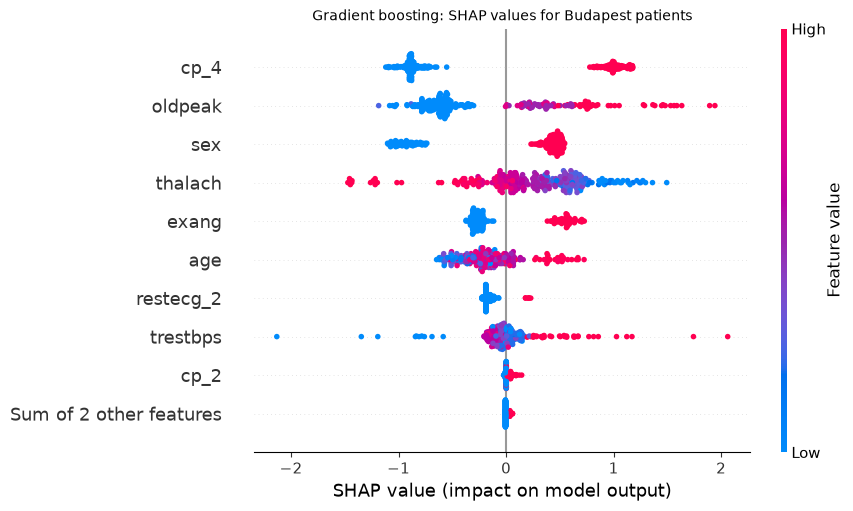

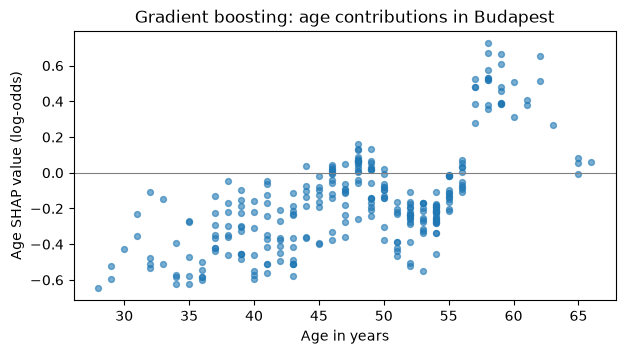

,size,median,min,max
age,,,,
"(0.0, 40.0]",59,-0.422,-0.647,-0.045
"(40.0, 50.0]",113,-0.118,-0.580,0.159
"(50.0, 60.0]",111,-0.179,-0.550,0.725
"(60.0, 70.0]",9,0.267,-0.006,0.654


In [6]:
sv_bud = explainer(design(bud))
shap.plots.beeswarm(sv_bud, show=False)
plt.title("Gradient boosting: SHAP values for Budapest patients", fontsize=10)
plt.show()

age = design(bud)["age"]
age_shap = sv_bud.values[:, X_cle.columns.get_loc("age")]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(age, age_shap, s=18, alpha=0.6)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set(xlabel="Age in years", ylabel="Age SHAP value (log-odds)",
       title="Gradient boosting: age contributions in Budapest")
plt.show()
display(pd.DataFrame({"age": age, "age SHAP": age_shap})
        .groupby(pd.cut(age, [0, 40, 50, 60, 70, np.inf]), observed=True)["age SHAP"]
        .agg(["size", "median", "min", "max"]).round(3))

✍️ **Your answer** (5–7 sentences):

1. The two models have similar AUROC at Budapest. Do they give patient 0 the same risk and the same reasons? Which input does each model weight most for this patient?
2. Which explanation is "correct"? (Hint: each is exact for its own model.)
3. In the beeswarm, how does age affect the gradient-boosted model's output? Is the effect a straight line, as in logistic regression?
4. What does this mean for a clinician shown one model's explanation as "the reason" for a risk?

**Answer**

Budapest AUROC was similar (0.875 for logistic regression and 0.884 for gradient boosting), but the estimated risk for Cleveland patient 0 was 60.4% and 44.1%, respectively. In both models the largest absolute contribution came from the chest-pain indicator `cp_4`, which lowered log-odds by 1.005 and 0.827, respectively. The largest upward contribution was oldpeak in the logistic model (+0.805 log-odds) and age in the boosted model (+0.500 log-odds). Both explanations are exact decompositions of their own model's log-odds relative to their own baseline. In the Budapest beeswarm and age plot, younger patients tended to receive negative age contributions, while older patients could receive positive contributions, with a median of −0.422 through age 40 and +0.267 above 60. Age contributions dipped in the early 50s, jumped near age 57, and varied among patients of the same age, unlike the logistic model's straight-line age contribution. A clinician should read each explanation as an account of the model that produced the estimate, since a different model with similar discrimination can emphasize different signs for the same patient.

## Part 2 — Saliency maps for the ECG 1D CNN (55 minutes)

### Load the beats and train the model

We retrain the Unit II architecture (four convolution blocks, global average pooling, two linear layers) for four epochs, using square-root class weights and keeping the epoch with the best validation macro-F1. On a laptop CPU each epoch takes about half a minute. Validation macro-F1 can go up and down between epochs; that is why the best epoch, not the last, is kept.

**Remember the limits of this dataset (Unit II):** rows are beats, not patients; the files contain no recording or patient IDs; and the source paper does not specify exactly where in the 187-sample window each beat was cut, so we locate the informative region from the data rather than assume it.

In [7]:
CANDIDATES = (sorted(Path("/kaggle/input").glob("**/mitbih_train.csv"))
              + [p / "module2/lectures/data/ecg_hb_clf/mitbih_train.csv" for p in (Path.cwd(), *Path.cwd().parents)]
              + [p / "module 2/lab4/ecg/data/mitbih_train.csv" for p in (Path.cwd(), *Path.cwd().parents)]
              + [DATA_DIR / "mitbih_train.csv"])
ECG_DIR = next((p.parent for p in CANDIDATES if p.is_file() and p.with_name("mitbih_test.csv").is_file()), None)
if ECG_DIR is None:
    raise FileNotFoundError("Could not find both MIT-BIH CSV files in the same folder. See 'Getting the ECG files' at the top of this notebook.")
print("ECG files found in folder:", ECG_DIR.name)

t0 = time.time()
train_arr = pd.read_csv(ECG_DIR / "mitbih_train.csv", header=None).to_numpy(np.float32)
test_arr = pd.read_csv(ECG_DIR / "mitbih_test.csv", header=None).to_numpy(np.float32)
X_tr_all, y_tr_all = train_arr[:, :187], train_arr[:, 187].astype(np.int64)
X_te, y_te = test_arr[:, :187], test_arr[:, 187].astype(np.int64)
CLASSES = ["N", "S", "V", "F", "Q"]
print(f"loaded in {time.time() - t0:.0f} s | train {len(X_tr_all):,} beats, test {len(X_te):,} beats")
print("training class counts:", dict(zip(CLASSES, np.bincount(y_tr_all))))
check("87,554 training beats", len(X_tr_all) == 87554)

X_fit, X_val, y_fit, y_val = train_test_split(X_tr_all, y_tr_all, test_size=0.1, stratify=y_tr_all, random_state=SEED)

ECG files found in folder: data


loaded in 2 s | train 87,554 beats, test 21,892 beats
training class counts: {'N': np.int64(72471), 'S': np.int64(2223), 'V': np.int64(5788), 'F': np.int64(641), 'Q': np.int64(6431)}
PASS  87,554 training beats


In [8]:
class ECGCNN(nn.Module):
    """Unit II architecture: input (n, 1, 187) -> 5 class logits."""
    def __init__(self, n_classes=5, base_filters=32, dropout=0.10):
        super().__init__()
        c1, c2, c3 = base_filters, base_filters * 2, base_filters * 4
        self.features = nn.Sequential(
            nn.Conv1d(1, c1, kernel_size=7, padding=3), nn.BatchNorm1d(c1), nn.ReLU(), nn.MaxPool1d(2), nn.Dropout(dropout / 2),
            nn.Conv1d(c1, c2, kernel_size=5, padding=2), nn.BatchNorm1d(c2), nn.ReLU(), nn.MaxPool1d(2), nn.Dropout(dropout),
            nn.Conv1d(c2, c3, kernel_size=5, padding=2), nn.BatchNorm1d(c3), nn.ReLU(), nn.MaxPool1d(2), nn.Dropout(dropout),
            nn.Conv1d(c3, c3, kernel_size=3, padding=1), nn.BatchNorm1d(c3), nn.ReLU(), nn.AdaptiveAvgPool1d(1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(c3, 64), nn.ReLU(), nn.Dropout(dropout + 0.05),
                                        nn.Linear(64, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


def to_tensor(x):
    return torch.from_numpy(np.ascontiguousarray(x)).unsqueeze(1)


@torch.no_grad()
def predict(model, x, batch=4096):
    model.eval()
    return np.concatenate([model(to_tensor(x[i:i + batch]).to(DEVICE)).argmax(1).cpu().numpy()
                           for i in range(0, len(x), batch)])


torch.manual_seed(SEED)
cnn = ECGCNN().to(DEVICE)
counts = np.bincount(y_fit)
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(np.sqrt(len(y_fit) / (5 * counts)), dtype=torch.float32).to(DEVICE))
optimizer = torch.optim.Adam(cnn.parameters(), lr=1e-3)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(to_tensor(X_fit), torch.from_numpy(y_fit)),
                                     batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(SEED))
best_f1, best_state = -1, None
for epoch in range(1, 5):
    t0 = time.time()
    cnn.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        loss_fn(cnn(xb.to(DEVICE)), yb.to(DEVICE)).backward()
        optimizer.step()
    f1 = f1_score(y_val, predict(cnn, X_val), average="macro")
    print(f"epoch {epoch}: validation macro-F1 {f1:.3f} ({time.time() - t0:.0f} s)")
    if f1 > best_f1:
        best_f1, best_state = f1, {k: v.detach().clone() for k, v in cnn.state_dict().items()}
cnn.load_state_dict(best_state)
cnn.eval()
pred_te = predict(cnn, X_te)
print(classification_report(y_te, pred_te, target_names=CLASSES, digits=3))

epoch 1: validation macro-F1 0.818 (40 s)


epoch 2: validation macro-F1 0.755 (50 s)


epoch 3: validation macro-F1 0.823 (55 s)


epoch 4: validation macro-F1 0.816 (44 s)


              precision    recall  f1-score   support

           N      0.980     0.979     0.979     18118
           S      0.745     0.599     0.664       556
           V      0.910     0.925     0.918      1448
           F      0.396     0.883     0.547       162
           Q      0.995     0.945     0.969      1608

    accuracy                          0.962     21892
   macro avg      0.805     0.866     0.815     21892
weighted avg      0.966     0.962     0.963     21892



### Where do the classes differ?

Before looking at saliency, look at the data. The plot shows the mean N beat and mean V beat in the test set, and where they differ most. A saliency method that highlights *these* positions is at least consistent with the data.

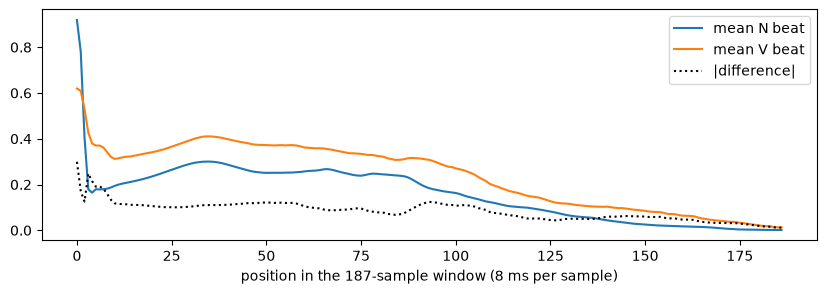

positions of largest N-V difference: [0 3 4 6 5 7 1 8]


In [9]:
mean_n, mean_v = X_te[y_te == 0].mean(0), X_te[y_te == 2].mean(0)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(mean_n, label="mean N beat"); ax.plot(mean_v, label="mean V beat")
ax.plot(np.abs(mean_n - mean_v), "k:", label="|difference|")
ax.set_xlabel("position in the 187-sample window (8 ms per sample)"); ax.legend()
plt.show()
print("positions of largest N-V difference:", np.argsort(-np.abs(mean_n - mean_v))[:8])

### Exercise 2.1 — Gradient and gradient × input

`gradient_map` returns $\partial\,\text{logit}_c / \partial x_t$ for each beat and position. Complete `grad_x_input_map`, which multiplies the gradient by the input value.

In [10]:
V = CLASSES.index("V")
idx_v = np.flatnonzero((y_te == V) & (pred_te == V))[:200]      # 200 correctly classified V beats
beats_v = X_te[idx_v]


def gradient_map(model, x, c):
    model.eval()
    xb = to_tensor(x).to(DEVICE).requires_grad_(True)
    (gradient,) = torch.autograd.grad(model(xb)[:, c].sum(), xb)
    return gradient.squeeze(1).cpu().numpy()


def grad_x_input_map(model, x, c):
    return gradient_map(model, x, c) * x


g_map = gradient_map(cnn, beats_v, V)
gi_map = grad_x_input_map(cnn, beats_v, V)
check("gradient x input differs from zero", np.abs(gi_map).sum() > 0)

PASS  gradient x input differs from zero


### Exercise 2.2 — Occlusion

Complete `occlusion_map`: slide a window of `width` samples along the beat in steps of `stride`, set the window to 0, and record the **drop in the predicted probability** of class `c`. Average the drops over all windows covering each position.

In [11]:
@torch.no_grad()
def class_prob(model, x, c):
    model.eval()
    return torch.softmax(model(to_tensor(x).to(DEVICE)), dim=1)[:, c].cpu().numpy()


def occlusion_map(model, x, c, width=10, stride=2):
    base = class_prob(model, x, c)
    total = np.zeros_like(x)
    covered = np.zeros(x.shape[1])
    n_samples = x.shape[1]
    if not 1 <= width <= n_samples or not 1 <= stride <= width:
        raise ValueError("Require 1 <= stride <= width <= number of samples")
    last_start = n_samples - width
    starts = list(range(0, last_start + 1, stride))
    # Include a final right-aligned window so the last sample is covered.
    if starts[-1] != last_start:
        starts.append(last_start)
    for start in starts:
        window = slice(start, start + width)
        occluded = x.copy()
        occluded[:, window] = 0
        total[:, window] += (base - class_prob(model, occluded, c))[:, None]
        covered[window] += 1
    return total / covered



o_map = occlusion_map(cnn, beats_v, V)
check("occlusion found some important positions", o_map.max() > 0.05)

PASS  occlusion found some important positions


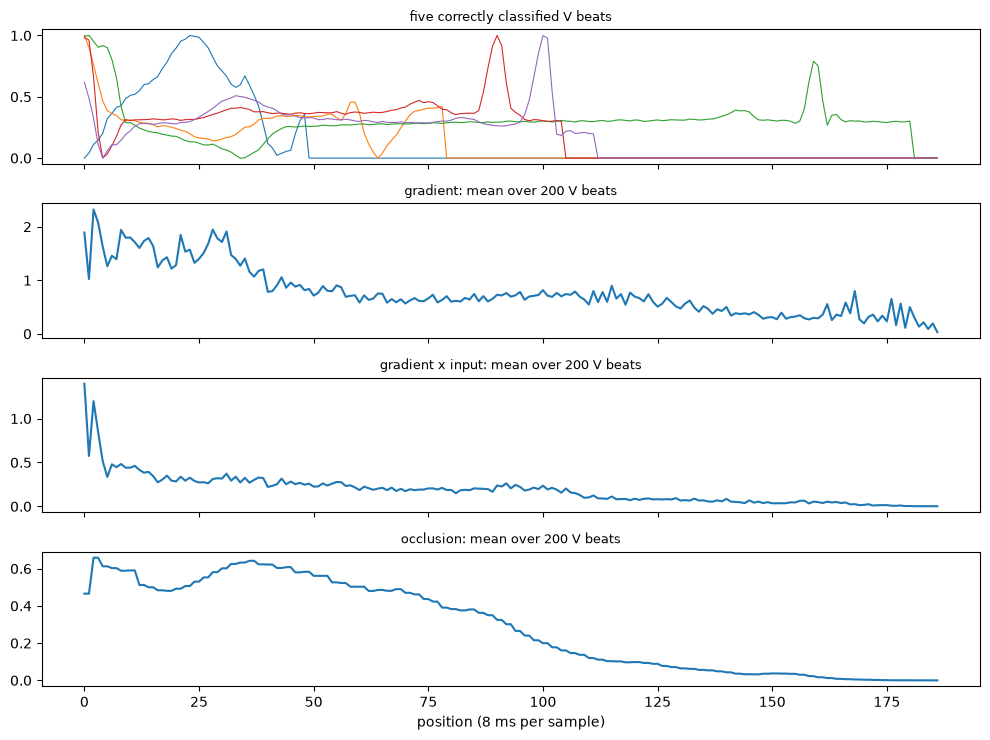

padding is 40% of all positions in these beats


,share of map on padding,top positions
gradient,0.213382,"[2, 3, 28, 8, 31]"
gradient x input,0.0,"[0, 2, 3, 1, 4]"
occlusion,0.00115,"[3, 2, 36, 37, 34]"


In [12]:
def beat_length(x):
    positions = np.arange(1, x.shape[1] + 1)
    return np.max(np.where(x != 0, positions, 0), axis=1)


def padding_mask(x):
    """True for the zero padding after the last non-zero sample of each beat."""
    return np.arange(x.shape[1])[None, :] >= beat_length(x)[:, None]


pad = padding_mask(beats_v)
maps = {"gradient": np.abs(g_map), "gradient x input": np.abs(gi_map), "occlusion": np.clip(o_map, 0, None)}
fig, axes = plt.subplots(len(maps) + 1, 1, figsize=(10, 7.5), sharex=True)
axes[0].plot(beats_v[:5].T, lw=0.8); axes[0].set_title("five correctly classified V beats", fontsize=9)
for ax, (name, m) in zip(axes[1:], maps.items()):
    ax.plot(m.mean(0)); ax.set_title(f"{name}: mean over {len(beats_v)} V beats", fontsize=9)
axes[-1].set_xlabel("position (8 ms per sample)")
plt.tight_layout(); plt.show()

summary = pd.DataFrame({name: {"share of map on padding": (m * pad).sum() / m.sum(),
                               "top positions": list(np.argsort(-m.mean(0))[:5])}
                        for name, m in maps.items()}).T
print(f"padding is {pad.mean():.0%} of all positions in these beats")
summary

✍️ **Your answer** (4–5 sentences): Where do the three methods put most of the importance? Does that agree with where the mean N and V beats differ? The gradient map puts some weight on the zero padding while gradient × input and occlusion put almost none there — explain why from how each method is computed.

**Answer**

All three maps peaked near the start of the beat, with gradient × input's top five positions confined to samples 0–4. The gradient also peaked around samples 28 and 31, and occlusion highlighted a secondary region around 34–37. The early peaks agree with the largest mean N–V differences, which occur in samples 0–8, while the later peaks show that the model's maps extend beyond the strongest group differences. Padding accounted for 40% of positions but received 21.3% of absolute gradient mass, 0% of gradient × input mass, and 0.115% of positive occlusion mass. A derivative can be nonzero at an input of zero, multiplication by that zero removes the attribution, and occluding an all-zero window changes nothing, although a window spanning the signal boundary can assign some of its drop to padded positions.

### Exercise 2.3 — Sanity check: randomise the model

Adebayo et al. (2018) asked: if we destroy what the model learned, does the map change? Below, an **untrained** network with random weights is created. Complete `sanity_check`: for each beat, compute the Spearman rank correlation between the absolute map from the trained model and from the random model, and return the median. A correlation near 1 means the map barely depends on what the model learned.

In [13]:
torch.manual_seed(123)
random_cnn = ECGCNN().to(DEVICE).eval()

METHODS = {"gradient": lambda m: np.abs(gradient_map(m, beats_v, V)),
           "gradient x input": lambda m: np.abs(grad_x_input_map(m, beats_v, V)),
           "occlusion": lambda m: np.abs(occlusion_map(m, beats_v, V))}


def sanity_check(method):
    trained, randomised = METHODS[method](cnn), METHODS[method](random_cnn)
    correlations = [
        spearmanr(original, random).statistic
        for original, random in zip(trained, randomised)
        if np.ptp(original) > 0 and np.ptp(random) > 0
    ]
    print(f"{method}: {len(correlations)}/{len(trained)} beats with defined Spearman correlation")
    return float(np.median(correlations)) if correlations else np.nan


sanity = pd.Series({name: sanity_check(name) for name in METHODS}, name="median Spearman (trained vs random)")
sanity

gradient: 200/200 beats with defined Spearman correlation
gradient x input: 200/200 beats with defined Spearman correlation


occlusion: 200/200 beats with defined Spearman correlation


gradient            0.046648
gradient x input    0.831731
occlusion           0.859662
Name: median Spearman (trained vs random), dtype: float64

✍️ **Your answer** (3–4 sentences): Which method fails the sanity check? Why might gradient × input look similar for a trained and a random network? (Hint: what does it multiply by?) Which method would you trust most for this model, and why?

**Answer**

Both gradient × input and occlusion showed high similarity after randomization, with median Spearman correlations of 0.832 and 0.860, respectively, so both performed poorly on this sanity check. Gradient × input multiplies both models' gradients by the same waveform, which preserves large-amplitude regions and forces both maps to share zeros on padding. Zero occlusion likewise changes the same input windows in both models, and all-zero windows contribute shared zero drops. I would trust the plain gradient most as a probe of what this CNN learned because its correlation fell to 0.047, while interpreting padding gradients as local sensitivity to perturbations of padded samples.

### Exercise 2.4 — Test a suspected shortcut: beat length

Beats are zero-padded to 187 samples, so a beat's **length** (position of its last non-zero sample) is visible to the model. If length alone separated classes, the model could use it as a shortcut. Complete the cell: compute the length of every beat, show the median length by class, and fit a logistic regression on length alone to separate V from N (train on `X_fit`, evaluate AUROC on the test set).

In [14]:
len_fit, len_te = beat_length(X_fit), beat_length(X_te)
median_lengths = pd.Series(len_te).groupby(pd.Series(y_te).map(dict(enumerate(CLASSES)))).median()
display(median_lengths.reindex(CLASSES).rename("median length"))

def length_auroc(positive_class):
    fit_pair = np.isin(y_fit, [0, positive_class])
    test_pair = np.isin(y_te, [0, positive_class])
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    model.fit(len_fit[fit_pair, None], y_fit[fit_pair] == positive_class)
    probabilities = model.predict_proba(len_te[test_pair, None])[:, 1]
    return roc_auc_score(y_te[test_pair] == positive_class, probabilities)


length_aurocs = pd.Series({f"{label} vs N": length_auroc(i) for i, label in enumerate(CLASSES) if i != 0},
                          name="test AUROC using only beat length")
auroc_length = length_aurocs["V vs N"]
display(length_aurocs.round(4))

N    106.0
S    108.0
V    112.0
F     78.0
Q    120.0
Name: median length, dtype: float64

S vs N    0.5377
V vs N    0.5512
F vs N    0.8937
Q vs N    0.6495
Name: test AUROC using only beat length, dtype: float64

✍️ **Your answer** (3–4 sentences): Is beat length a strong shortcut for V versus N? Is it for any other class (look at the medians)? What does this test add that the saliency maps alone could not tell you?

**Answer**

Beat length was a weak shortcut for V versus N, with test AUROC 0.551 and median lengths of 112 and 106 samples, respectively. The F class had the clearest length signal, with a median of 78 samples and an F-versus-N AUROC of 0.894. S and Q had medians of 108 and 120 and weaker pairwise AUROCs against N of 0.538 and 0.650. The held-out test measures how much class information length alone carries, while establishing whether the CNN uses length would require a separate controlled intervention.

## Part 3 — Reflection (15 minutes)

✍️ **Your answer** (8–10 sentences):

1. A hospital wants to show SHAP explanations next to each heart-disease risk "so clinicians can see why". Using Part 1, write two cautions for them.
2. A colleague shows you an attractive gradient × input saliency map for an ECG model as evidence that "the model looks at the right place". Using Part 2, what would you ask them to do first?
3. For which purpose in Session 5's table were the methods in this lab most useful: finding problems during development, auditing, bedside explanation, or proof of correctness? Give one example from your results.

**Answer**

My first caution to the hospital would be to label SHAP as a model-specific explanation and identify the baseline and log-odds scale. In this lab the two models ranked Budapest patients similarly, yet they estimated Cleveland patient 0's risk at 60.4% and 44.1% and assigned their largest upward contributions to different inputs. My second caution would be to validate the risk estimates on the intended hospital population and treat the SHAP values as associations learned by the model. The SHAP additivity check verifies how the score was assembled, while claims about calibration or the causes of disease need separate evidence. For the ECG map, I would first ask for the same gradient × input analysis on the same beats with a randomly initialized network, comparing the absolute maps by per-beat rank correlation. The median correlation of 0.832 illustrates how multiplication by the waveform can preserve the apparent shape of the explanation after randomization. I would then compare gradient and occlusion with the observed waveform differences and check the role of padding. Of the Session 5 purposes, I found these methods most useful for finding problems during development. The F-versus-N length-only AUROC of 0.894 motivates testing the CNN on length-matched beats to see whether preprocessing drives some of its performance.

## Grading rubric

| Criterion | Points |
|---|---:|
| Part 1: permutation importance implemented with grouped inputs and repeat ranges; interpretation | 20 |
| Part 1: SHAP additivity check; comparison of the two models' explanations; non-linear effect described | 20 |
| Part 2: gradient × input and occlusion implemented; maps compared with where classes differ; padding behaviour explained | 25 |
| Part 2: sanity check implemented and interpreted; beat-length shortcut tested | 20 |
| Part 3: reflection that is specific, uses results, and does not over-claim | 15 |
| **Total** | **100** |

These points apply to this lab only. They are not course-assessment weights.

## References

- [Session 5 lecture notes](../lectures/session-05-explainability-skills.md).
- Lundberg SM, Lee S-I. [A unified approach to interpreting model predictions](https://arxiv.org/abs/1705.07874). *NeurIPS* 2017. — SHAP; [SHAP documentation](https://shap.readthedocs.io/).
- Adebayo J et al. [Sanity checks for saliency maps](https://arxiv.org/abs/1810.03292). *NeurIPS* 2018.
- Zeiler MD, Fergus R. [Visualizing and understanding convolutional networks](https://arxiv.org/abs/1311.2901). *ECCV* 2014. — occlusion.
- Kachuee M, Fazeli S, Sarrafzadeh M. [ECG heartbeat classification: a deep transferable representation](https://arxiv.org/abs/1805.00794). 2018. — source of the processed beats.
- UCI Machine Learning Repository. [Heart Disease dataset](https://archive.ics.uci.edu/dataset/45/heart+disease) (doi:10.24432/C52P4X), CC BY 4.0.